# CV-STQA — Phase 0: MAC-VQA Setup & Data Pipeline

**Phase 0 only — no model training.**

This notebook:
- finds the Kaggle `MAC-VQA Videos` and `VQA-MOS` inputs
- reads `MOS.txt`
- matches MOS records to video filenames
- checks the dataset
- creates Protocol A train/validation/test splits
- samples frames
- extracts a 7×7 patch grid
- verifies the PyTorch Dataset/DataLoader

The project plan defines Phase 0 as the setup stage and requires the dataloader to reproduce the MAC-VQA clip count and MOS distributions before proceeding.


## Expected Kaggle structure

```text
/kaggle/input/
├── MAC-VQA Videos/
│   └── videos/
│       ├── 1-11.mp4
│       ├── 1-13.mp4
│       └── ...
└── VQA-MOS/
    ├── MOS.txt
    └── MOS-descriptions.txt
```

No uploading/copying is required.


In [1]:
# ============================================================
# 1. Imports and configuration
# ============================================================

import os
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

KAGGLE_INPUT = Path("/kaggle/input")

NUM_FRAMES = 16
GRID_SIZE = 7
IMAGE_SIZE = 224

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

MOS_COLUMNS = ["SR", "S", "U", "TSV", "B", "O"]

print("Configuration loaded.")
print("Seed:", SEED)
print("Frames per clip:", NUM_FRAMES)
print("Grid:", f"{GRID_SIZE} × {GRID_SIZE}")
print("Image size:", IMAGE_SIZE)


Configuration loaded.
Seed: 42
Frames per clip: 16
Grid: 7 × 7
Image size: 224


## 2. Locate the videos and MOS files

In [2]:
# ============================================================
# 2. Discover files
# ============================================================

VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv"}

all_videos = []
mos_files = []
mos_description_files = []

for root, dirs, files in os.walk(KAGGLE_INPUT):
    for fname in files:
        path = Path(root) / fname

        if path.suffix.lower() in VIDEO_EXTENSIONS:
            all_videos.append(path)

        if fname.lower() == "mos.txt":
            mos_files.append(path)

        if fname.lower() == "mos-descriptions.txt":
            mos_description_files.append(path)

print("Videos found:", len(all_videos))
print("MOS.txt found:", len(mos_files))
print("MOS-descriptions.txt found:", len(mos_description_files))

print("\nMOS files:")
for p in mos_files:
    print(p)

print("\nSample videos:")
for p in all_videos[:20]:
    print(p)


Videos found: 1000
MOS.txt found: 1
MOS-descriptions.txt found: 1

MOS files:
/kaggle/input/datasets/miruthulajmm/vqa-mos/MOS.txt

Sample videos:
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/14-17.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/18-24.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/13-6.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/31-25.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/68-6.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/15-22.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/43-10.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/2-26.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/54-3.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/49-1.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/2-16.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/60-9.mp4
/kaggle/input/datasets/miruthulajmm/mac-vqa-v

In [3]:
# ============================================================
# 3. Select inputs automatically
# ============================================================

if len(mos_files) != 1:
    raise RuntimeError(f"Expected one MOS.txt, found {len(mos_files)}")

MOS_FILE = mos_files[0]

MOS_DESCRIPTION_FILE = (
    mos_description_files[0]
    if mos_description_files else None
)

# Prefer videos inside a folder named "videos"
VIDEO_FILES = [
    p for p in all_videos
    if p.parent.name.lower() == "videos"
]

if not VIDEO_FILES:
    VIDEO_FILES = all_videos

if not VIDEO_FILES:
    raise RuntimeError("No video files found.")

print("MOS file:", MOS_FILE)
print("Video files selected:", len(VIDEO_FILES))


MOS file: /kaggle/input/datasets/miruthulajmm/vqa-mos/MOS.txt
Video files selected: 1000


## 3. Inspect `MOS-descriptions.txt`

In [4]:
# ============================================================
# 4. Display MOS description
# ============================================================

if MOS_DESCRIPTION_FILE:
    with open(
        MOS_DESCRIPTION_FILE,
        "r",
        encoding="utf-8",
        errors="replace"
    ) as f:
        print(f.read())
else:
    print("MOS-descriptions.txt not found.")


videoname,TSV,B,SR,S,U,O


## 4. Inspect the raw `MOS.txt`

In [5]:
# ============================================================
# 5. Display first MOS lines
# ============================================================

with open(
    MOS_FILE,
    "r",
    encoding="utf-8",
    errors="replace"
) as f:
    mos_lines = f.readlines()

print("Total lines:", len(mos_lines))
print()

for i, line in enumerate(mos_lines[:30], 1):
    print(f"{i:03d}: {line.rstrip()}")


Total lines: 1000

001: 1-14.mp4,0.9235,1.3311,1.356,1.0388,0.92656,1.846
002: 1-18.mp4,0.9454,1.5686,0.895,0.74001,1.3656,2.456
003: 1-22.mp4,0.60707,1.7066,1.6,0,0.256,1.4056
004: 1-4.mp4,2.5644,1.8566,2.45,1.9687,2.9056,4.1097
005: 10-12.mp4,1.6549,1.756,1.4035,1.8715,1.5,2.8304
006: 12-14.mp4,1.1,0.42323,0.81818,0.62802,0.245,1.1232
007: 12-15.mp4,0.75,1.6665,0.7856,1.2613,0.4565,1.4
008: 12-3.mp4,2.3771,1.0656,0.854,1.7482,1.6023,3.02
009: 12-9.mp4,2.328,1.5656,1.2656,1.179,1.0565,2.8989
010: 13-10.mp4,1.428,1.22,1.1566,0.92561,1.2261,2.6565
011: 13-13.mp4,2.1834,2.9656,1.266,1.7187,2.023,3.3099
012: 14-13.mp4,1.3651,1.1566,1.2929,1.1168,1.0704,2.423
013: 14-14.mp4,1.45,1.1656,1.4246,1.7829,1.2065,2.3
014: 14-21.mp4,0.5,0.8656,1.685,0.26209,0.235,1.1519
015: 15-24.mp4,1.7772,1.756,2.565,2.1944,2.03,3.156
016: 16-1.mp4,2.5085,2.9665,2.898,2.6494,2.9,4.7
017: 16-14.mp4,2.287,0.7656,1.901,2.1173,2.123,4.0772
018: 16-15.mp4,2.1504,0.12356,2.656,1.8526,1.4023,2.789
019: 16-16.mp4,2.222

## 5. Parse `MOS.txt`

The parser treats each record as:

```text
video_id + six MOS values
```

For example, a record corresponding to `1-11.mp4` should have a video ID of `1-11`.

If the file contains headers/comments/blank lines, they are skipped.


In [14]:
# ============================================================
# 6. Parse MOS.txt
# ============================================================

# MOS-descriptions.txt gives the actual order:
# videoname, TSV, B, SR, S, U, O

MOS_COLUMNS = ["TSV", "B", "SR", "S", "U", "O"]

mos_df = pd.read_csv(
    MOS_FILE,
    header=None,
    names=["video_id"] + MOS_COLUMNS,
    skipinitialspace=True
)

# Remove accidental whitespace
mos_df["video_id"] = (
    mos_df["video_id"]
    .astype(str)
    .str.strip()
)

# Convert MOS values to numeric
for col in MOS_COLUMNS:
    mos_df[col] = pd.to_numeric(
        mos_df[col],
        errors="coerce"
    )

print("Parsed annotation records:", len(mos_df))

display(mos_df.head())

print("\nColumns:")
print(mos_df.columns.tolist())

print("\nMissing values:")
display(mos_df.isna().sum())

Parsed annotation records: 1000


,video_id,TSV,B,SR,S,U,O
0,1-14.mp4,0.92350,1.3311,1.3560,1.03880,0.92656,1.8460
1,1-18.mp4,0.94540,1.5686,0.8950,0.74001,1.36560,2.4560
2,1-22.mp4,0.60707,1.7066,1.6000,0.00000,0.25600,1.4056
3,1-4.mp4,2.56440,1.8566,2.4500,1.96870,2.90560,4.1097
4,10-12.mp4,1.65490,1.7560,1.4035,1.87150,1.50000,2.8304



Columns:
['video_id', 'TSV', 'B', 'SR', 'S', 'U', 'O']

Missing values:


video_id    0
TSV         0
B           0
SR          0
S           0
U           0
O           0
dtype: int64

## 6. Validate the MOS data

In [15]:
# ============================================================
# 7. MOS validation
# ============================================================

missing_columns = [
    c for c in MOS_COLUMNS
    if c not in mos_df.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing MOS columns: {missing_columns}"
    )

print("MOS columns:", MOS_COLUMNS)
print("Annotation shape:", mos_df.shape)

print("\nMissing values:")
display(mos_df[MOS_COLUMNS].isna().sum())

print("\nDuplicate video IDs:")
print(mos_df["video_id"].duplicated().sum())

print("\nUnique video IDs:")
print(mos_df["video_id"].nunique())


MOS columns: ['TSV', 'B', 'SR', 'S', 'U', 'O']
Annotation shape: (1000, 7)

Missing values:


TSV    0
B      0
SR     0
S      0
U      0
O      0
dtype: int64


Duplicate video IDs:
0

Unique video IDs:
1000


## 7. Match MOS records to video files

In [16]:
# ============================================================
# 8. Match MOS records to video files
# ============================================================

video_lookup = {}

for path in VIDEO_FILES:

    # Store both:
    # "1-14.mp4"
    # "1-14"

    video_lookup[path.name] = path
    video_lookup[path.stem] = path


# Clean annotation IDs
mos_df["video_id"] = (
    mos_df["video_id"]
    .astype(str)
    .str.strip()
)

# Match exact filename first
mos_df["video_path"] = mos_df["video_id"].map(
    lambda x: video_lookup.get(x)
)

matched = mos_df["video_path"].notna().sum()
unmatched = mos_df["video_path"].isna().sum()

print("MOS records:", len(mos_df))
print("Matched videos:", matched)
print("Unmatched:", unmatched)

if unmatched > 0:
    print("\nFirst unmatched IDs:")
    display(
        mos_df.loc[
            mos_df["video_path"].isna(),
            ["video_id"]
        ].head(30)
    )

MOS records: 1000
Matched videos: 1000
Unmatched: 0


## 8. Dataset count check

In [17]:
# ============================================================
# 9. Count checks
# ============================================================

print("Actual video files:", len(VIDEO_FILES))
print("Actual MOS records:", len(mos_df))
print("Matched pairs:", matched)

print("\nProject-plan reference:")
print("Clips: 1000")
print("Exams: 40")

if len(VIDEO_FILES) == 1000:
    print("\nVIDEO COUNT: PASS")
else:
    print(
        f"\nVIDEO COUNT: CHECK — found {len(VIDEO_FILES)}"
    )

if len(mos_df) == 1000:
    print("MOS COUNT: PASS")
else:
    print(
        f"MOS COUNT: CHECK — found {len(mos_df)}"
    )


Actual video files: 1000
Actual MOS records: 1000
Matched pairs: 1000

Project-plan reference:
Clips: 1000
Exams: 40

VIDEO COUNT: PASS
MOS COUNT: PASS


## 9. MOS statistics and distributions

In [18]:
# ============================================================
# 10. MOS statistics
# ============================================================

mos_stats = mos_df[MOS_COLUMNS].describe().T
mos_stats = mos_stats[
    ["count", "mean", "std", "min", "max"]
]

display(mos_stats)


,count,mean,std,min,max
TSV,1000.0,1.738266,0.655125,0.000000,3.0
B,1000.0,1.617256,0.804055,0.000000,3.0
SR,1000.0,1.618782,0.677266,0.099618,3.0
S,1000.0,1.550427,0.777195,0.000000,3.0
U,1000.0,1.722382,0.717845,0.000000,3.0
O,1000.0,3.075494,1.012061,1.000000,5.0


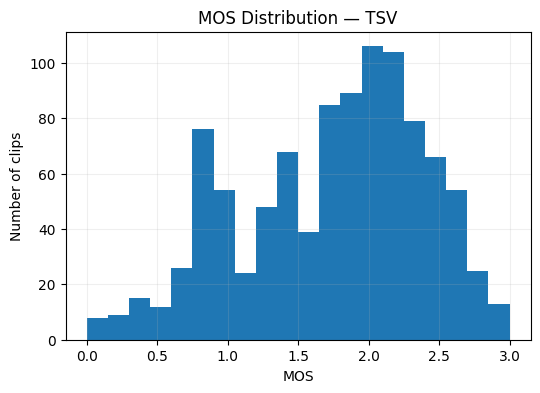

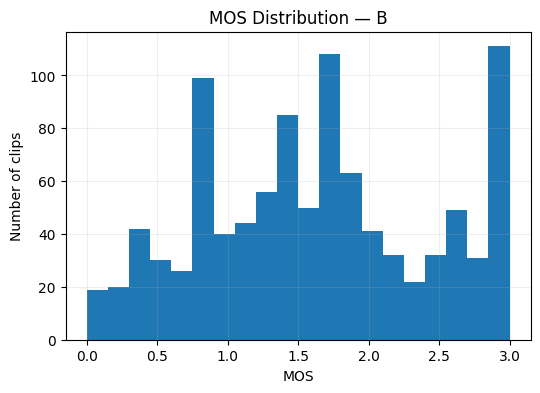

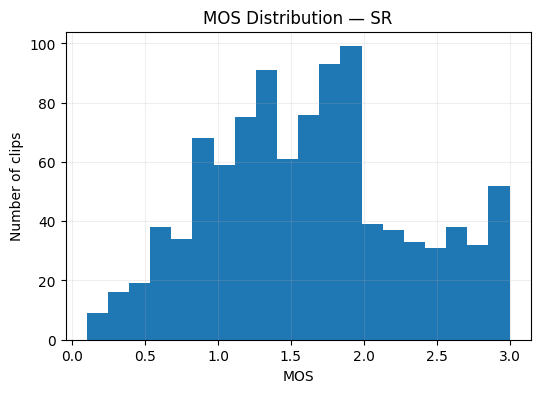

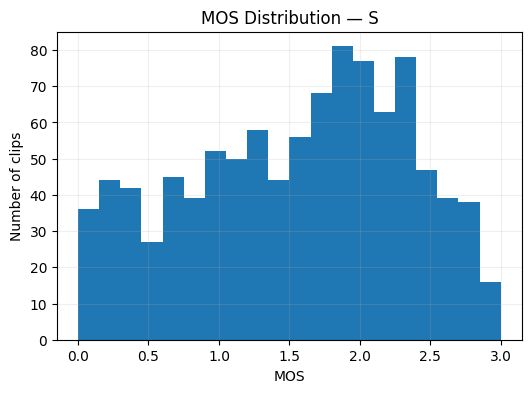

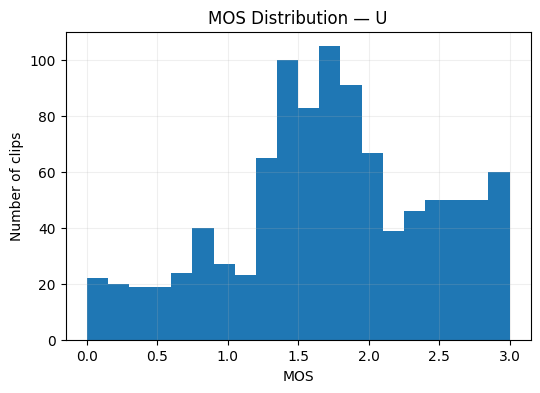

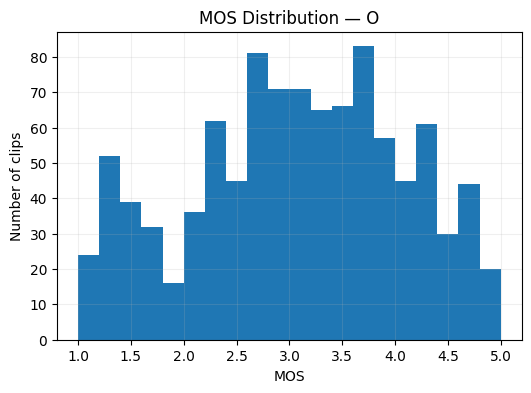

In [19]:
# ============================================================
# 11. MOS distributions
# ============================================================

for col in MOS_COLUMNS:

    plt.figure(figsize=(6, 4))
    plt.hist(mos_df[col].dropna(), bins=20)

    plt.title(f"MOS Distribution — {col}")
    plt.xlabel("MOS")
    plt.ylabel("Number of clips")
    plt.grid(alpha=0.2)

    plt.show()


## 10. Protocol A split

A fixed random seed is used so the same train/validation/test clips can be reused for every later model.


In [20]:
# ============================================================
# 12. Create Protocol A split
# ============================================================

rng = np.random.default_rng(SEED)

indices = np.arange(len(mos_df))
rng.shuffle(indices)

n = len(indices)

n_train = int(TRAIN_RATIO * n)
n_val = int(VAL_RATIO * n)

train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]

train_df = mos_df.iloc[train_idx].reset_index(drop=True)
val_df = mos_df.iloc[val_idx].reset_index(drop=True)
test_df = mos_df.iloc[test_idx].reset_index(drop=True)

print("Total:", len(mos_df))
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Sum:", len(train_df) + len(val_df) + len(test_df))


Total: 1000
Train: 700
Validation: 150
Test: 150
Sum: 1000


In [21]:
# ============================================================
# 13. Verify split leakage
# ============================================================

train_ids = set(train_df["video_id"])
val_ids = set(val_df["video_id"])
test_ids = set(test_df["video_id"])

print("Train ∩ Val :", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Val ∩ Test  :", len(val_ids & test_ids))

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("\nSPLIT LEAKAGE CHECK: PASS")


Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0

SPLIT LEAKAGE CHECK: PASS


In [22]:
# ============================================================
# 14. Save splits
# ============================================================

SPLIT_DIR = Path("/kaggle/working/phase0_splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(SPLIT_DIR / "val.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

split_config = {
    "protocol": "A_random",
    "seed": SEED,
    "train_ratio": TRAIN_RATIO,
    "val_ratio": VAL_RATIO,
    "test_ratio": TEST_RATIO,
    "num_frames": NUM_FRAMES,
    "grid_size": GRID_SIZE,
    "image_size": IMAGE_SIZE
}

with open(
    SPLIT_DIR / "split_config.json",
    "w"
) as f:
    json.dump(split_config, f, indent=2)

print("Saved:")
for p in sorted(SPLIT_DIR.iterdir()):
    print(" ", p.name)


Saved:
  split_config.json
  test.csv
  train.csv
  val.csv


## 11. Deterministic frame sampling

In [23]:
# ============================================================
# 15. Frame sampler
# ============================================================

import cv2


def sample_video_frames(
    video_path,
    num_frames=NUM_FRAMES,
    image_size=IMAGE_SIZE
):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    fps = float(
        cap.get(cv2.CAP_PROP_FPS)
    )

    if total_frames <= 0:
        cap.release()
        raise RuntimeError(
            f"No readable frames: {video_path}"
        )

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames,
        dtype=int
    )

    frames = []

    for idx in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(idx)
        )

        success, frame = cap.read()

        if not success:
            continue

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frame = cv2.resize(
            frame,
            (image_size, image_size)
        )

        frames.append(frame)

    cap.release()

    if not frames:
        raise RuntimeError(
            f"Could not decode frames: {video_path}"
        )

    return (
        np.stack(frames),
        frame_indices,
        fps,
        total_frames
    )


In [24]:
# ============================================================
# 16. Test frame sampling
# ============================================================

TEST_VIDEO = Path(
    train_df.iloc[0]["video_path"]
)

frames, frame_indices, fps, total_frames = (
    sample_video_frames(TEST_VIDEO)
)

print("Video:", TEST_VIDEO)
print("Total frames:", total_frames)
print("FPS:", fps)
print("Sampled indices:", frame_indices)
print("Returned shape:", frames.shape)


Video: /kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/68-11.mp4
Total frames: 249
FPS: 25.0
Sampled indices: [  0  16  33  49  66  82  99 115 132 148 165 181 198 214 231 248]
Returned shape: (16, 224, 224, 3)


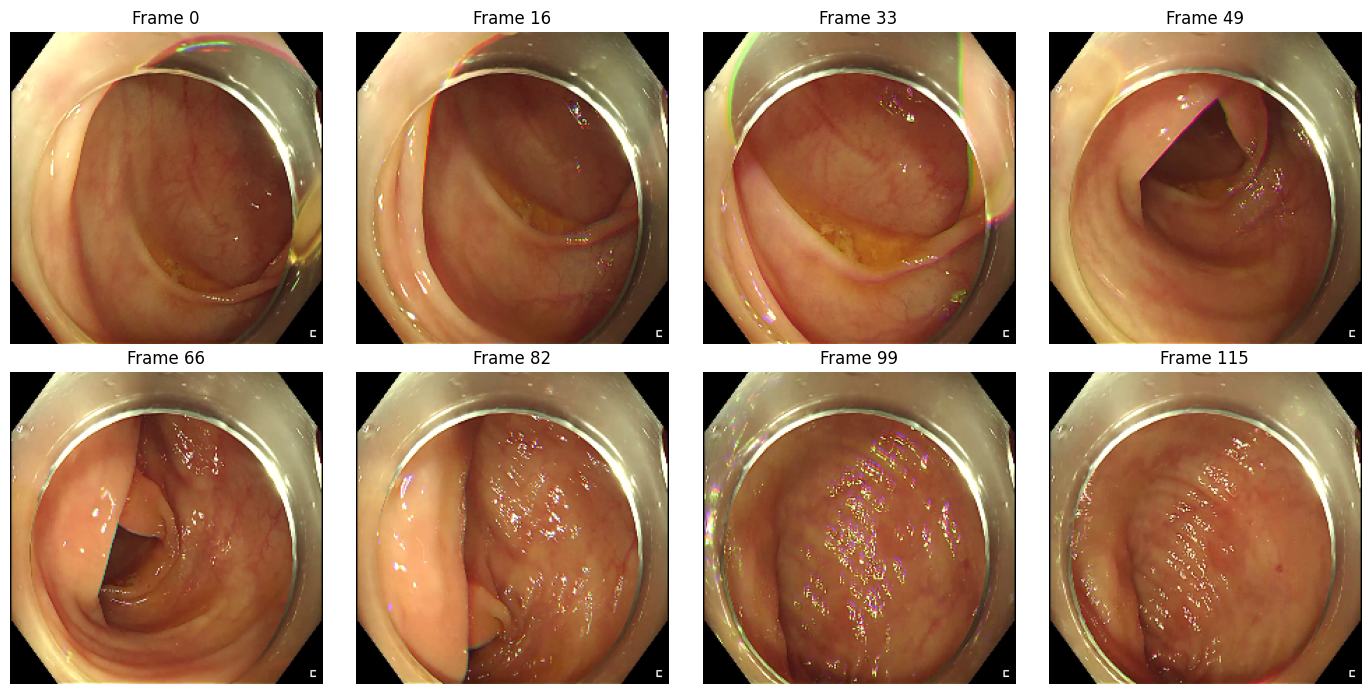

In [25]:
# ============================================================
# 17. Visualize sampled frames
# ============================================================

n_show = min(len(frames), 8)

fig, axes = plt.subplots(
    2, 4, figsize=(14, 7)
)

axes = axes.flatten()

for i in range(n_show):
    axes[i].imshow(frames[i])
    axes[i].set_title(
        f"Frame {frame_indices[i]}"
    )
    axes[i].axis("off")

for i in range(n_show, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()


## 12. 7 × 7 spatial patch extraction

In [28]:
# ============================================================
# 18. 7x7 patch extractor
# ============================================================

def extract_grid_patches(
    frame,
    grid_size=GRID_SIZE
):

    H, W, C = frame.shape

    patch_h = H // grid_size
    patch_w = W // grid_size

    patches = []

    
    for row in range(grid_size):

        for col in range(grid_size):

            y1 = row * patch_h
            x1 = col * patch_w

            y2 = (
                H
                if row == grid_size - 1
                else (row + 1) * patch_h
            )

            x2 = (
                W
                if col == grid_size - 1
                else (col + 1) * patch_w
            )

            patches.append(
                frame[y1:y2, x1:x2]
            )

    return np.array(
        patches,
        dtype=np.uint8
    )


In [29]:
# ============================================================
# 19. Test patch extraction
# ============================================================

patches = extract_grid_patches(frames[0])

print("Frame shape:", frames[0].shape)
print("Number of patches:", len(patches))
print("Patch shape:", patches[0].shape)
print("Expected:", GRID_SIZE * GRID_SIZE)

assert len(patches) == 49

print("\n7x7 PATCH CHECK: PASS")


Frame shape: (224, 224, 3)
Number of patches: 49
Patch shape: (32, 32, 3)
Expected: 49

7x7 PATCH CHECK: PASS


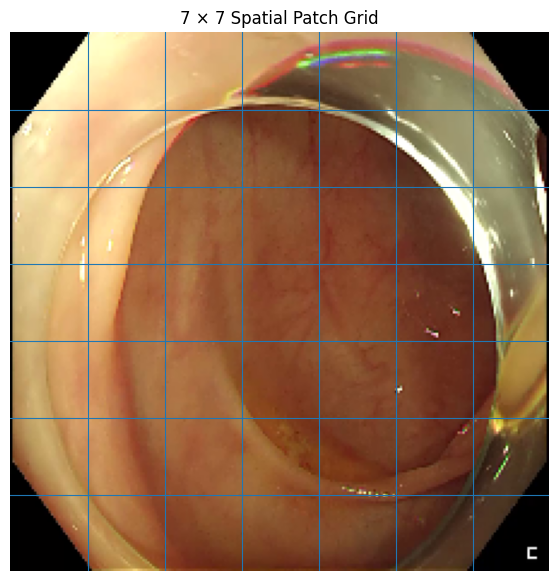

In [30]:
# ============================================================
# 20. Visualize the 7x7 grid
# ============================================================

frame = frames[0]
H, W, _ = frame.shape

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(frame)

for i in range(1, GRID_SIZE):
    ax.axhline(
        i * H / GRID_SIZE,
        linewidth=0.8
    )
    ax.axvline(
        i * W / GRID_SIZE,
        linewidth=0.8
    )

ax.set_title("7 × 7 Spatial Patch Grid")
ax.axis("off")

plt.show()


## 13. PyTorch Dataset

The common Phase 0 representation contains:

- sampled frames
- 49 patches per frame
- six MOS values
- video ID/path
- sampled frame indices


In [31]:
# ============================================================
# 21. PyTorch Dataset
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader


class MACVQADataset(Dataset):

    def __init__(
        self,
        dataframe,
        num_frames=NUM_FRAMES,
        grid_size=GRID_SIZE,
        image_size=IMAGE_SIZE
    ):
        self.df = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.grid_size = grid_size
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        video_id = row["video_id"]
        video_path = Path(row["video_path"])

        frames, frame_indices, fps, total_frames = (
            sample_video_frames(
                video_path,
                num_frames=self.num_frames,
                image_size=self.image_size
            )
        )

        patch_sequence = np.stack([
            extract_grid_patches(
                frame,
                grid_size=self.grid_size
            )
            for frame in frames
        ])

        frames_tensor = torch.from_numpy(
            frames
        ).permute(
            0, 3, 1, 2
        ).float() / 255.0

        patches_tensor = torch.from_numpy(
            patch_sequence
        ).permute(
            0, 1, 4, 2, 3
        ).float() / 255.0

        mos_tensor = torch.tensor(
            row[MOS_COLUMNS].astype(float).values,
            dtype=torch.float32
        )

        return {
            "video_id": video_id,
            "video_path": str(video_path),
            "frames": frames_tensor,
            "patches": patches_tensor,
            "mos": mos_tensor,
            "frame_indices": torch.tensor(
                frame_indices,
                dtype=torch.long
            )
        }


In [32]:
# ============================================================
# 22. Create datasets
# ============================================================

train_dataset = MACVQADataset(train_df)
val_dataset = MACVQADataset(val_df)
test_dataset = MACVQADataset(test_df)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Train: 700
Validation: 150
Test: 150


In [33]:
# ============================================================
# 23. Inspect one dataset sample
# ============================================================

sample = train_dataset[0]

print("Video ID:", sample["video_id"])
print("Video path:", sample["video_path"])

print("\nFrames shape:")
print(sample["frames"].shape)

print("\nPatches shape:")
print(sample["patches"].shape)

print("\nMOS shape:")
print(sample["mos"].shape)

print("MOS values:")
print(sample["mos"].tolist())

print("\nFrame indices:")
print(sample["frame_indices"].tolist())


Video ID: 68-11.mp4
Video path: /kaggle/input/datasets/miruthulajmm/mac-vqa-videos/videos/68-11.mp4

Frames shape:
torch.Size([16, 3, 224, 224])

Patches shape:
torch.Size([16, 49, 3, 32, 32])

MOS shape:
torch.Size([6])
MOS values:
[2.002500057220459, 2.123500108718872, 1.8600000143051147, 1.7211999893188477, 1.812600016593933, 3.5139999389648438]

Frame indices:
[0, 16, 33, 49, 66, 82, 99, 115, 132, 148, 165, 181, 198, 214, 231, 248]


In [34]:
# ============================================================
# 24. Dataloader smoke test
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

batch = next(iter(train_loader))

print("Dataloader test successful.")

for key, value in batch.items():

    if torch.is_tensor(value):
        print(key, "->", tuple(value.shape))
    else:
        print(key, "->", type(value))


Dataloader test successful.
video_id -> <class 'list'>
video_path -> <class 'list'>
frames -> (1, 16, 3, 224, 224)
patches -> (1, 16, 49, 3, 32, 32)
mos -> (1, 6)
frame_indices -> (1, 16)


# PHASE 0 — FINAL GATE

### Dataset
- [ ] MAC-VQA videos located
- [ ] `MOS.txt` located
- [ ] Six MOS dimensions verified
- [ ] Clip count checked
- [ ] Video ↔ MOS matching checked

### MOS
- [ ] Missing values checked
- [ ] Duplicate IDs checked
- [ ] MOS statistics calculated
- [ ] MOS distributions inspected

### Protocol A
- [ ] Fixed seed
- [ ] Train/validation/test split created
- [ ] No split leakage
- [ ] Split files saved

### Video processing
- [ ] Videos decode
- [ ] Deterministic frame sampling works
- [ ] Frames visually inspected

### Spatial processing
- [ ] 7×7 grid works
- [ ] 49 patches/frame verified
- [ ] Grid visually inspected

### Dataloader
- [ ] Frames returned
- [ ] Patches returned
- [ ] Six MOS values returned
- [ ] Train/validation/test loaders work

**Do not start M0 until the clip count and MOS distributions have been compared against the MAC-VQA reference and these checks pass.**
